# MarineGuard AI — Cross-Camera Study

Train and evaluate a separate YOLO26n using the camera-held-out SeaClear split. This study does not replace the original selected model.


## 1. Setup

Set the recorded paths and training environment.


In [1]:
%pip -q install "ultralytics==8.4.216" pyyaml pandas pillow matplotlib

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from collections import Counter
import pandas as pd
import yaml
import torch
import ultralytics

MANIFEST = Path('/content/drive/MyDrive/MarineGuard_Validation_Improvement/MarineGuard_v2_verified_seaclear_manifest')
DATA = MANIFEST / 'data.yaml'
RUNS = Path('/content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/runs')
RUN_NAME = 'yolo26n_seaclear_v2_30epochs'
TRAIN_DIR = RUNS / RUN_NAME
BEST = TRAIN_DIR / 'weights' / 'best.pt'
LAST = TRAIN_DIR / 'weights' / 'last.pt'
REPORT_DIR = Path('/content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports')
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print('Ultralytics:', ultralytics.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Select Runtime > Change runtime type > T4 GPU before training. CPU is okay for read-only checks.')
print('Manifest:', MANIFEST)
print('Run:', TRAIN_DIR)


Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.216
CUDA available: True
GPU: Tesla T4
Manifest: /content/drive/MyDrive/MarineGuard_Validation_Improvement/MarineGuard_v2_verified_seaclear_manifest
Run: /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/runs/yolo26n_seaclear_v2_30epochs


## 2. Verify split

Check manifests, labels, and source assignment; prepare a Bistrina-only validation subset.


In [2]:
# Audit input manifests and create the Bistrina-only validation configuration.
assert DATA.is_file(), f'Missing v2 config: {DATA}. Run notebook 05 first.'
with DATA.open() as f:
    cfg = yaml.safe_load(f)
assert cfg['nc'] == 2 and list(cfg['names'].values()) == ['Net', 'Rope'], cfg

splits = {}
for split in ('train', 'val'):
    manifest_path = Path(cfg[split])
    assert manifest_path.is_file(), f'Missing {split} image-list: {manifest_path}'
    images = [Path(s.strip()) for s in manifest_path.read_text().splitlines() if s.strip()]
    assert len(images) == len(set(images)), f'Duplicate image paths in {split}'
    assert all(im.is_file() for im in images), f'Missing {split} image(s)'
    counts = Counter()
    for image in images:
        # Exact folder convention of MarineGuard_YOLO_Fixed:
        # .../images/train/name.jpg -> .../labels/train/name.txt
        assert '/images/' in image.as_posix(), f'Unexpected layout: {image}'
        label = Path(image.as_posix().replace('/images/', '/labels/')).with_suffix('.txt')
        assert label.is_file(), f'Missing annotation: {label}'
        for line in label.read_text().splitlines():
            if line.strip():
                bits = line.split()
                assert len(bits) == 5, f'Malformed annotation: {label}'
                cls = int(bits[0]); assert cls in (0, 1)
                counts[cls] += 1
    splits[split] = images
    print(f'{split}: {len(images)} images; Net={counts[0]}; Rope={counts[1]}')
    assert len(images) == {'train': 1461, 'val': 850}[split], 'Unexpected split size'
    assert counts[0] == {'train': 589, 'val': 371}[split], 'Unexpected Net count'
    assert counts[1] == {'train': 1405, 'val': 642}[split], 'Unexpected Rope count'

assert set(splits['train']).isdisjoint(splits['val']), 'Train/val images overlap'
provenance = pd.read_csv(MANIFEST / 'all_images_provenance_and_assignments.csv')
kept = provenance[provenance['proposed_split'].isin(['train','val'])]
a = set(kept.loc[kept.proposed_split=='train', 'source_group'])
b = set(kept.loc[kept.proposed_split=='val', 'source_group'])
assert not a.intersection(b), f'Source group leakage: {a & b}'
assert 'Bistrina/Bluerobotics HD' in b and 'Bistrina/Bluerobotics HD' not in a
print('PASS: File paths, class counts, and source-camera separation verified.')
print('NOTE: Camera separation is not independent geographic Net generalization.')

# Create a second, Bistrina-only evaluation manifest. The original 850-image
# validation manifest remains unchanged and is used during training.
BISTRINA_VAL_LIST = REPORT_DIR / 'bistrina_heldout_val_images.txt'
BISTRINA_DATA = REPORT_DIR / 'data_bistrina_eval.yaml'
bis_sources = {'Bistrina/Bluerobotics HD', 'Bistrina/SIP-E323CV'}
bis_rows = kept[(kept.proposed_split == 'val') & (kept.source_group.isin(bis_sources))]
assert len(bis_rows) == 760, 'Unexpected Bistrina holdout count'
assert int(bis_rows.nets.sum()) == 371 and int(bis_rows.ropes.sum()) == 633, 'Unexpected Bistrina object counts'
BISTRINA_VAL_LIST.write_text('\n'.join(sorted(bis_rows.image_path.tolist())) + '\n', encoding='utf-8')
bis_yaml = dict(cfg)
bis_yaml['val'] = str(BISTRINA_VAL_LIST)
with BISTRINA_DATA.open('w') as f:
    yaml.safe_dump(bis_yaml, f, sort_keys=False)
print('Bistrina-only held-out validation: 760 images, 371 Nets, 633 Ropes')
print('Bistrina-only data config:', BISTRINA_DATA)


train: 1461 images; Net=589; Rope=1405
val: 850 images; Net=371; Rope=642
PASS: File paths, class counts, and source-camera separation verified.
NOTE: Camera separation is not independent geographic Net generalization.
Bistrina-only held-out validation: 760 images, 371 Nets, 633 Ropes
Bistrina-only data config: /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/data_bistrina_eval.yaml


## 3. Fresh training

Train from pretrained YOLO26n weights or resume a saved interrupted run.


In [3]:
# Train, resume, or reuse the fresh YOLO26n checkpoint for this experiment.
# Change this to 'resume' if Colab disconnected after training began,
# or 'skip' when BEST already exists and you want evaluation/demo only.
TRAIN_MODE = 'new'  # 'new' | 'resume' | 'skip'
assert TRAIN_MODE in ('new', 'resume', 'skip')

from ultralytics import YOLO

if TRAIN_MODE == 'new':
    assert torch.cuda.is_available(), 'Training needs a GPU. Select Runtime > Change runtime type > T4 GPU.'
    assert not TRAIN_DIR.exists(), f'Existing run at {TRAIN_DIR}. Use TRAIN_MODE="resume" or "skip".'
    print('Starting fresh YOLO26n from pretrained weights. NOT continuing the original checkpoint.')
    model = YOLO('yolo26n.pt')
    model.train(
        data=str(DATA), epochs=30, patience=8, imgsz=640,
        batch=8, optimizer='SGD', lr0=0.01, lrf=0.01,
        momentum=0.937, seed=42, deterministic=True,
        device=0, workers=2,
        hsv_h=0.01, hsv_s=0.30, hsv_v=0.20,
        translate=0.05, scale=0.20, fliplr=0.5,
        flipud=0.0, degrees=0.0, mosaic=0.30,
        close_mosaic=8, mixup=0.0,
        save=True, plots=True, project=str(RUNS),
        name=RUN_NAME, exist_ok=False, verbose=False
    )
elif TRAIN_MODE == 'resume':
    assert torch.cuda.is_available(), 'Resume requires a GPU.'
    assert LAST.is_file(), f'Cannot resume; missing {LAST}'
    model = YOLO(str(LAST))
    model.train(resume=True)
else:
    assert BEST.is_file(), f'No finished best.pt at {BEST}'
    print('Training skipped. Loading saved best.pt.')

assert BEST.is_file(), f'No best.pt produced at {BEST}'
print('BEST CHECKPOINT:', BEST)
print('LAST CHECKPOINT:', LAST if LAST.exists() else 'Not present')


Starting fresh YOLO26n from pretrained weights. NOT continuing the original checkpoint.
New https://pypi.org/project/ultralytics/8.4.218 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/MarineGuard_Validation_Improvement/MarineGuard_v2_verified_seaclear_manifest/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01,

## 4. Full holdout evaluation

Evaluate all 850 validation images using source-camera-separated data.


In [4]:
# Evaluate the full source-camera-held-out SeaClear validation split.
from ultralytics import YOLO
import json

assert BEST.is_file(), f'Missing trained checkpoint: {BEST}'
model = YOLO(str(BEST))
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
metrics = model.val(
    data=str(DATA), split='val', imgsz=640, batch=4,
    device=DEVICE, workers=0, conf=0.001,
    plots=True, project=str(REPORT_DIR),
    name='v2_validation', exist_ok=True, verbose=False
)

row = {
    'experiment': 'SeaClear v2 camera-held-out',
    'train_images': 1461, 'val_images': 850,
    'net_gt_in_val': 371, 'rope_gt_in_val': 642,
    'mAP50': float(metrics.box.map50),
    'mAP50-95': float(metrics.box.map),
    'precision': float(metrics.box.mp),
    'recall': float(metrics.box.mr),
    'net_mAP50-95': float(metrics.box.maps[0]),
    'rope_mAP50-95': float(metrics.box.maps[1]),
}

classes_seen = [int(x) for x in metrics.box.ap_class_index]
for idx, cls in enumerate(classes_seen):
    cname = ['net', 'rope'][cls]
    row[f'{cname}_precision'] = float(metrics.box.p[idx])
    row[f'{cname}_recall'] = float(metrics.box.r[idx])
    row[f'{cname}_mAP50'] = float(metrics.box.ap50[idx])

summary = pd.DataFrame([row])
display(summary.T.rename(columns={0:'value'}))
out_csv = REPORT_DIR / 'v2_validation_metrics.csv'
summary.to_csv(out_csv, index=False)
with (REPORT_DIR / 'v2_experiment_metadata.json').open('w') as f:
    json.dump({
        'dataset_yaml':str(DATA), 'checkpoint':str(BEST),
        'data_scope':'Bistrina cross-camera SeaClear-only; includes additional non-Bistrina negatives/rope examples',
        'original_training_overlap':'Old checkpoint saw camera-held-out images; do not compare old checkpoint on this split as unbiased baseline',
        'excluded':'193 CleanSea cutouts and 300 unverified extra negatives',
        'ultralytics_version':ultralytics.__version__,
        'metrics':row
    },f,indent=2)
print('Validation results saved:', out_csv)
print('Validation plots:', REPORT_DIR / 'v2_validation')


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.0 ms, read: 126.3±27.4 MB/s, size: 144.3 KB)
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/train.cache... 850 images, 129 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 850/850 274.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 213/213 12.7it/s 16.8s
                   all        850       1013      0.671      0.439      0.506      0.327
Speed: 0.3ms preprocess, 3.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/v2_validation


,value
experiment,SeaClear v2 camera-held-out
train_images,1461
val_images,850
net_gt_in_val,371
rope_gt_in_val,642
mAP50,0.506244
mAP50-95,0.326562
precision,0.671133
recall,0.4393
net_mAP50-95,0.374845


Validation results saved: /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/v2_validation_metrics.csv
Validation plots: /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/v2_validation


## 5. Bistrina-only evaluation

Measure performance on 760 images from held-out Bistrina cameras.


In [5]:
bistrina_metrics = model.val(
    data=str(BISTRINA_DATA), split='val', imgsz=640, batch=4,
    device=DEVICE, workers=0, conf=0.001,
    plots=True, project=str(REPORT_DIR), name='bistrina_only_validation',
    exist_ok=True, verbose=False
)
brow = {
    'experiment': 'Bistrina-only cross-camera holdout',
    'train_images': 1461, 'val_images': 760,
    'net_gt_in_val':371, 'rope_gt_in_val':633,
    'mAP50':float(bistrina_metrics.box.map50),
    'mAP50-95':float(bistrina_metrics.box.map),
    'precision':float(bistrina_metrics.box.mp),
    'recall':float(bistrina_metrics.box.mr),
    'net_mAP50-95':float(bistrina_metrics.box.maps[0]),
    'rope_mAP50-95':float(bistrina_metrics.box.maps[1]),
}
for idx, cls in enumerate(bistrina_metrics.box.ap_class_index):
    cname = ['net','rope'][int(cls)]
    brow[f'{cname}_precision'] = float(bistrina_metrics.box.p[idx])
    brow[f'{cname}_recall'] = float(bistrina_metrics.box.r[idx])
    brow[f'{cname}_mAP50'] = float(bistrina_metrics.box.ap50[idx])

combined = pd.DataFrame([row, brow])
display(combined.T)
combined_path = REPORT_DIR/'v2_full_vs_bistrina_validation.csv'
combined.to_csv(combined_path, index=False)
print('Saved comparison:', combined_path)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 109.8±25.9 MB/s, size: 137.8 KB)
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/train... 760 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 760/760 244.4it/s 3.1s
val: New cache created: /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/train.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 190/190 12.2it/s 15.6s
                   all        760       1004       0.63      0.474      0.512       0.33
Speed: 0.3ms preprocess, 3.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/bistrina_only_validation


,0,1
experiment,SeaClear v2 camera-held-out,Bistrina-only cross-camera holdout
train_images,1461,1461
val_images,850,760
net_gt_in_val,371,371
rope_gt_in_val,642,633
mAP50,0.506244,0.511719
mAP50-95,0.326562,0.329564
precision,0.671133,0.630495
recall,0.4393,0.474287
net_mAP50-95,0.374845,0.375346


Saved comparison: /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/v2_full_vs_bistrina_validation.csv


## 6. Bounding-box review

Compare ground truth with predicted Net and Rope boxes.


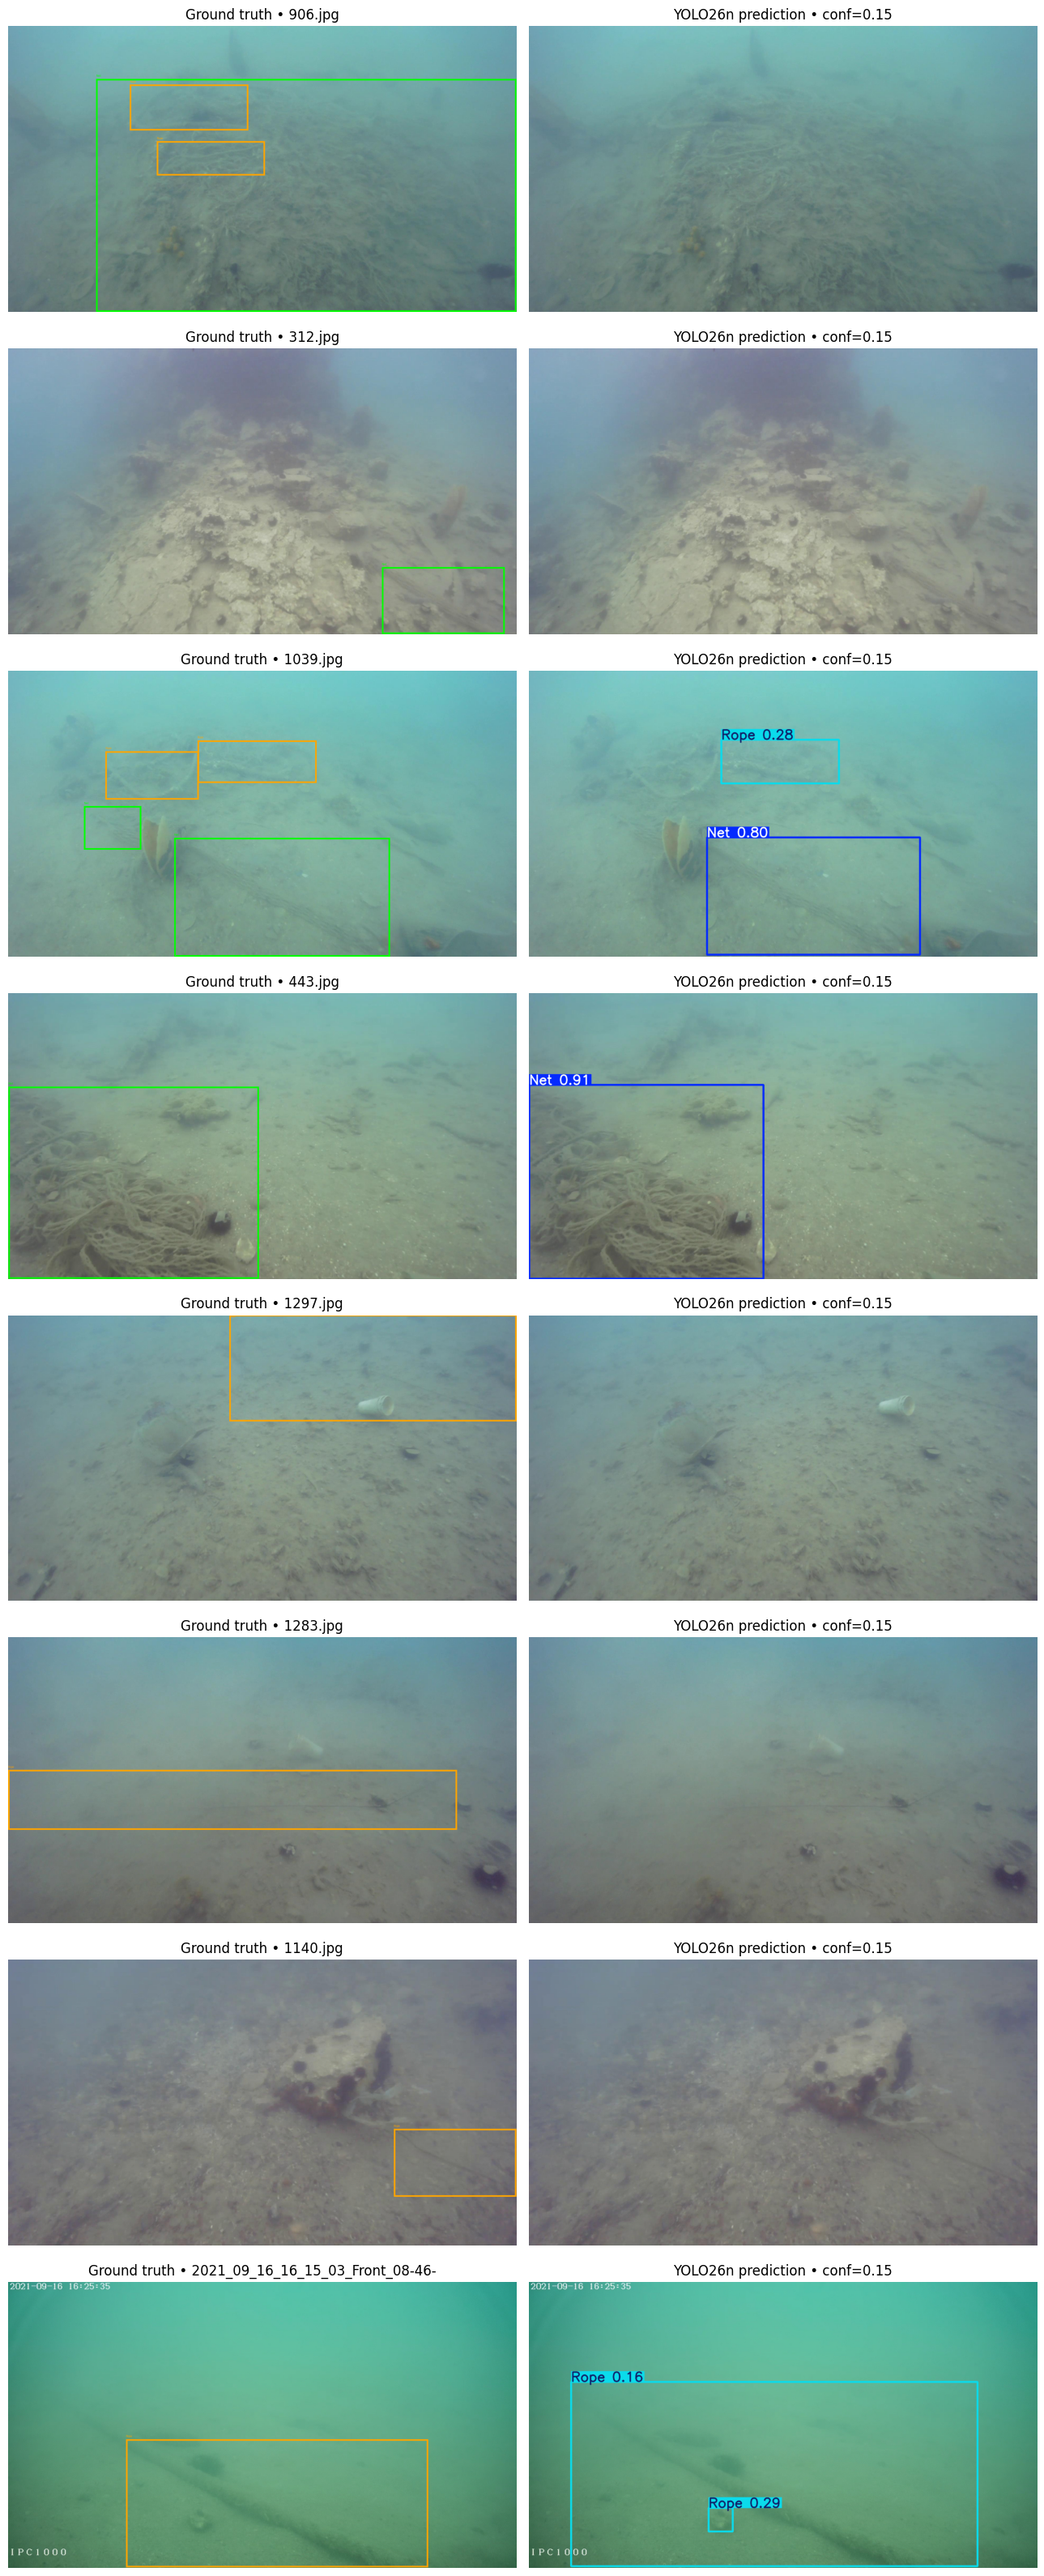

Visual comparison saved: /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/v2_heldout_gt_vs_predictions.png


In [6]:
# Visualize ground-truth and predicted boxes on held-out examples.
from PIL import Image, ImageDraw
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import random

model = YOLO(str(BEST))
# Prefer samples containing each target category; choose only held-out-camera images
val_images = splits['val']

def gt_classes(path):
    label = Path(path.as_posix().replace('/images/', '/labels/')).with_suffix('.txt')
    return {int(line.split()[0]) for line in label.read_text().splitlines() if line.strip()}

rng = random.Random(42)
net_imgs = [p for p in val_images if 0 in gt_classes(p)]
rope_imgs = [p for p in val_images if 1 in gt_classes(p)]
chosen = rng.sample(net_imgs, min(4, len(net_imgs)))
chosen_paths = {p.as_posix() for p in chosen}
rope_remaining = [p for p in rope_imgs if p.as_posix() not in chosen_paths]
chosen += rng.sample(rope_remaining, min(4, len(rope_remaining)))

fig, axs = plt.subplots(len(chosen), 2, figsize=(13, 4 * len(chosen)), squeeze=False)
for i, image_path in enumerate(chosen):
    base = Image.open(image_path).convert('RGB')
    W, H = base.size
    gt = base.copy(); d = ImageDraw.Draw(gt)
    label = Path(image_path.as_posix().replace('/images/', '/labels/')).with_suffix('.txt')
    for line in label.read_text().splitlines():
        if not line.strip(): continue
        cls, xc, yc, bw, bh = map(float, line.split())
        x1=(xc-bw/2)*W; y1=(yc-bh/2)*H; x2=(xc+bw/2)*W; y2=(yc+bh/2)*H
        color = 'lime' if int(cls)==0 else 'orange'
        d.rectangle([x1,y1,x2,y2], outline=color, width=max(2,W//300))
        d.text((x1,max(0,y1-18)), ['Net','Rope'][int(cls)], fill=color)
    prediction=model.predict(source=str(image_path), imgsz=640,conf=0.15,
                             device=DEVICE,verbose=False)[0]
    import cv2
    pred=Image.fromarray(cv2.cvtColor(prediction.plot(), cv2.COLOR_BGR2RGB))
    axs[i,0].imshow(gt); axs[i,0].set_title('Ground truth • '+image_path.name[:32]); axs[i,0].axis('off')
    axs[i,1].imshow(pred); axs[i,1].set_title('YOLO26n prediction • conf=0.15'); axs[i,1].axis('off')
plt.tight_layout()
fig_path=REPORT_DIR/'v2_heldout_gt_vs_predictions.png'
fig.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print('Visual comparison saved:', fig_path)


## 7. Uploaded-image check

Run one qualitative inference example using the Version 2 checkpoint.


Saving Screenshot 2026-11-23 174057.png to Screenshot 2026-11-23 174057.png


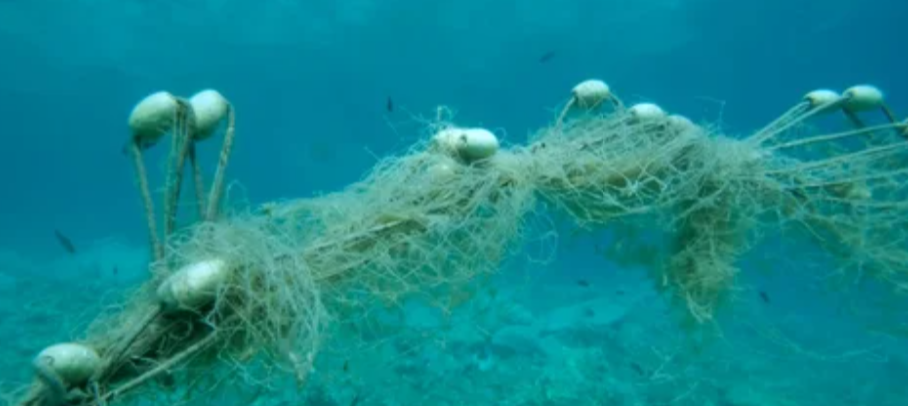

Detections: 0
Saved: /content/drive/MyDrive/MarineGuard_Model_Selection/bistrina_camera_holdout_v2/reports/Screenshot 2026-11-23 174057_marineguard_prediction.png


In [10]:
from google.colab import files
from IPython.display import display
from PIL import Image
import cv2

uploaded = files.upload()
if uploaded:
    demo_path = next(iter(uploaded))
    demo_result = model.predict(
        source=demo_path, imgsz=640, conf=0.15,
        device=DEVICE, verbose=False
    )[0]
    demo_plot = Image.fromarray(cv2.cvtColor(demo_result.plot(), cv2.COLOR_BGR2RGB))
    display(demo_plot)
    demo_name = Path(demo_path).stem + '_marineguard_prediction.png'
    demo_out = REPORT_DIR / demo_name
    demo_plot.save(demo_out)
    print('Detections:', len(demo_result.boxes))
    print('Saved:', demo_out)
else:
    print('No image uploaded; nothing changed.')


## 8. Optional external diagnostic

Keep the previously inspected TrashCan split separate from training and tuning.


In [8]:
# Optionally evaluate the already-examined TrashCan diagnostic set.
# Optional: set to True to run this diagnostic on the already exposed TrashCan subset.
RUN_TRASHCAN_DIAGNOSTIC = False

if RUN_TRASHCAN_DIAGNOSTIC:
    fixed_yaml = Path('/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/data.yaml')
    assert fixed_yaml.is_file()
    test_metrics = model.val(
        data=str(fixed_yaml), split='test', imgsz=640,
        batch=4, device=DEVICE, workers=0, conf=0.001,
        plots=True, project=str(REPORT_DIR),
        name='trashcan_diagnostic_only', exist_ok=True
    )
    test_row = {
        'mAP50':float(test_metrics.box.map50),
        'mAP50-95':float(test_metrics.box.map),
        'precision':float(test_metrics.box.mp),
        'recall':float(test_metrics.box.mr),
        'net_mAP50-95':float(test_metrics.box.maps[0]),
        'rope_mAP50-95':float(test_metrics.box.maps[1]),
    }
    display(pd.DataFrame([test_row]))
    pd.DataFrame([test_row]).to_csv(REPORT_DIR/'v2_trashcan_diagnostic_metrics.csv',index=False)
else:
    print('Skipped optional TrashCan diagnostic.')


Skipped optional TrashCan diagnostic.


## 9. Optional demo

Launch a temporary Colab interface for the Version 2 checkpoint.


In [9]:
# Optionally launch a temporary Colab-based Gradio demonstration.
# Optional toggle. Running creates a temporary Gradio interface in this Colab session.
LAUNCH_DEMO_UI = False

if LAUNCH_DEMO_UI:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'])
    import gradio as gr
    from PIL import Image
    import numpy as np
    import cv2

    def infer_marineguard(img):
        if img is None:
            return None
        image = np.array(img.convert('RGB'))
        result = model.predict(source=image, imgsz=640, conf=0.15,
                               device=DEVICE, verbose=False)[0]
        return Image.fromarray(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))

    demo = gr.Interface(
        fn=infer_marineguard,
        inputs=gr.Image(type='pil', label='Upload underwater image'),
        outputs=gr.Image(type='pil', label='Detected Nets and Ropes'),
        title='MarineGuard AI — Bistrina-Focused Prototype',
        description='YOLO26n prototype. Trained using SeaClear. Predictions are not guaranteed and require review.'
    )
    demo.launch(share=True)
else:
    print('Skipped optional browser interface.')


Skipped optional browser interface.


## 10. Common-split comparison

Evaluate both checkpoints on the original 178-image validation set. Original mAP50–95: 0.3271; Version 2: 0.1504. Because both data and training conditions differ, this is not an unbiased generalization ranking. The original model remains the Version 1 selection.


In [11]:
from ultralytics import YOLO
import pandas as pd

ROOT = "/content/drive/MyDrive/MarineGuard_Model_Selection"

checkpoints = {
    "Original YOLO26n": (
        f"{ROOT}/budget20_30_v1/runs_budget20_30_v1/"
        "final/yolo26n/weights/best.pt"
    ),
    "Version 2 YOLO26n": (
        f"{ROOT}/bistrina_camera_holdout_v2/runs/"
        "yolo26n_seaclear_v2_30epochs/weights/best.pt"
    )
}

data_yaml = (
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed/data.yaml"
)

rows = []

for name, checkpoint in checkpoints.items():
    metrics = YOLO(checkpoint).val(
        data=data_yaml,
        split="val",
        imgsz=640,
        batch=4,
        device=0,
        conf=0.001,
        workers=0,
        plots=False
    )

    rows.append({
        "Model": name,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "Net mAP50-95": metrics.box.maps[0],
        "Rope mAP50-95": metrics.box.maps[1]
    })

display(pd.DataFrame(rows).round(4))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 159.9±51.6 MB/s, size: 181.4 KB)
val: Scanning /content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed/labels/val.cache... 178 images, 100 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 178/178 49.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 13.0it/s 3.5s
                   all        178         78      0.697      0.667      0.533      0.327
                   Net          7          7       0.45      0.857      0.408      0.299
                  Rope         71         71      0.944      0.478      0.658      0.355
Speed: 0.3ms preprocess, 4.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n sum

,Model,mAP50,mAP50-95,Net mAP50-95,Rope mAP50-95
0,Original YOLO26n,0.5334,0.3271,0.2994,0.3547
1,Version 2 YOLO26n,0.2447,0.1504,0.0341,0.2666
